## **Praktikum Sistem Komunikasi Multimedia/Sistem dan Teknologi Multimedia**



---



* Nama: Cantika Angela Putri
* NIM: 221331004
* Kelas: 3A-TC

## Modul 4: Move to Front (MTF)
## Bagian Encoder

# Instruksi!

Sebelum melakukan pekerjaan di bawah, ada beberapa hal yang harus diperhatikan.

* Waktu pengerjaan sesuai dengan deadline pada GCR.
* GCR akan ditutup setelah jam tersebut.
* Waktu submit ke GCR berpengaruh pada nilai, lebih cepat akan mendapat nilai tambahan.
* Jika ada kendala saat upload file ipynb, maka bisa dengan menyematkan link google collabnya pada kolom submission tugas di GCR.
* Jika ada pertanyaan bisa diajukan di grup perkuliahan.

*selamat mengerjakan*

### Pendahuluan

Pada modul sebelumnya, kita telah mencoba membuat encoder-decoder kompresi data dengan
menggunakan teknik Run Length Encoding. Pada kali ini, kita akan mencoba membuat encoder-decoder kompresi data yang masih serumpun dengan metode RLE, tetapi dengan detail yang
berbeda, yaitu metode Move to Front. Konsepnya adalah mengupayakan agar simbol-simbol yang
sering muncul ditempatkan pada posisi-posisi awal dengan nomor indeks rendah, sehingga bila
di-encode, cukup menggunakan panjang bit yang sedikit.
Metode ini dimulai dengan sederet simbol dengan posisi setiap simbol direkam dalam indeks. Bila
ada data yang ingin dikirim, maka indeks data tersebut dikirim, dan simbol yang sama pada list
dipindahkan ke posisi terdepan. Begitu seterusnya sampai semua data berhasil dikirim. Sebagai
contoh, bila kita memiliki sederet simbol S = < A, B, C, D, E > dengan indeks posisi I = < 0, 1, 2,
3, 4 >, maka untuk mengirim data D = < D, C, D, E, A, A, B, E, B >, proses yang terjadi dapat
dilihat pada tabel 1.

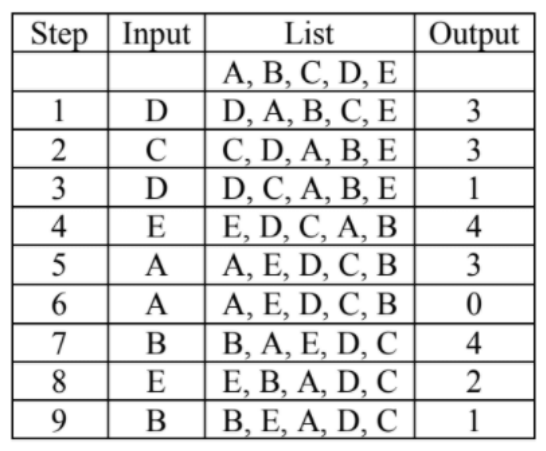

Proses decode nya diawali dengan list yang sama serta menerima input nomor indeks. Dengan
asumsi tidak ada kesalahan pada media transmisi, maka data asalnya dapat direkonstruksi
kembali seperti yang dapat dilihat pada tabel 2.


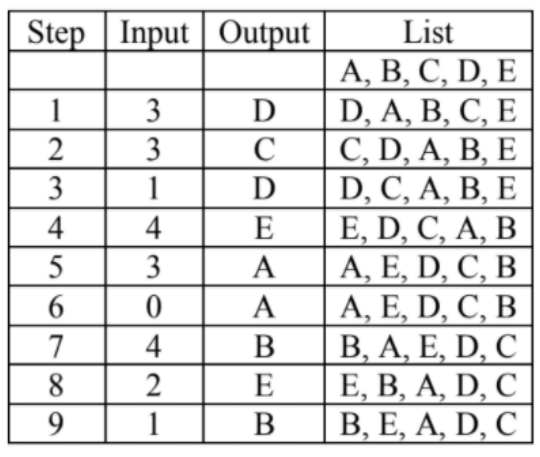

### Langkah-langkah Percobaan

---

Pada percobaan pendahuluan sebelumnya konsep move to front atau memindahkan simbol ke depan dictionary belum akan diimplementasikan.

Fokus dari modul ini, mahasiswa mampu mencetak nilai index datastream input terhadap dictionary yang telah ditetapkan **kemudian melakukan proses move to front pada program tersebut**. Adapun langkah yang dapat membantu untuk bisa membuat program tersebut adalah sebagai berikut:

1. Program harus bisa melakukan scan satu persatu terhadap tiap huruf pada datastream secara berurutan dari awal (seperti yang sudah pernah dilakukan sebelumnya). Contoh pada datastream = DCDEAABEB;
program harus bisa mulai mengambil data pertama yaitu huruf D.

2. Kemudian jika sudah bisa membaca huruf D atau huruf pertama pada datastream, huruf tersebut akan dilakukan perbandingan (mencari kesamaan dengan semua simbol di dictionary). Contoh saat datastream membaca huruf D tadi, huruf tersebut dibandingkan dengan dictionary= ABCDE; dengan indexnya 0123. Huruf D akan dibandingkan dengan A, kemudian B, kemudian C, dan kemudian D; saat bertemu huruf yang sama output akan mencetak index D pada dictionary, yaitu index 3.

**3. Setelah selasai membandingkan dengan simbol dan berhasil mencetak, tambahkan program untuk melakukan *replace* terhadap dictionary symbol yang lama. Dictionary yang sebelumnya ABCDE diganti dengan DABCE.**

4. Lanjutkan pembacaan datastream ke index berikutnya. Setelah selesai membaca huruf D, lanjutkan pembacaan ke huruf C. Lakukan step yang sama seperti di atas untuk membandingkan dengan dictionary dan proses MTF. Sehingga akan mengeluarkan output index 2. Maka setelah itu output akan menjadi output=33..

5. Lakukan proses tersebut berulang hingga akhir huruf/symbol pada datastream.
6. Sehingga untuk datastream=DCDEAABEB akan menghasilkan output=331430421

**Instruksi:**

Sebagai modifikasi dari program Move to Front pendahuluan sebelumnya buatlah program untuk bisa mendeteksi angka urutan pada data input terhadap dictionary yang kita buat (deratan simbol) dan diikuti dengan proses MTF pada dictionary.

Deretan symbol yang digunakan adalah:
S = < A, B, C, D, E >

Sedangkan data stream / data input yang digunakan adalah:
datastream = < D, C, D, E, A, A, B, E, B >


a. Insertkan flowchartnya pada laman text di bawah.

b. Tuliskan programnya pada laman code di bawah.

Output yang harus dihasilkan:

datastream = < D, C, D, E, A, A, B, E, B >

output = 331430421



In [9]:
dictionary = ['A', 'B', 'C', 'D', 'E'] # Inisialisasi dictionary

datastream = ['D', 'C', 'D', 'E', 'A', 'A', 'B', 'E', 'B'] # Datastream yang akan diproses

output = [] #list untuk menyimpan output

# Proses Move to Front
for char in datastream:
    index = dictionary.index(char)  # Mencari index karakter di dictionary
    output.append(index) # Menambahkan index ke output
    dictionary.insert(0, dictionary.pop(index)) #proses move to front
    print(f"Setelah memproses '{char}', dictionary = {dictionary}") #Mencetak dictionary yang baru setelah Move to Front

print("\nOutput indeks =", output) # Mencetak output indeks
print("Output datastream =", ''.join(datastream)) # Output datastream yang dihasilkan


Setelah memproses 'D', dictionary = ['D', 'A', 'B', 'C', 'E']
Setelah memproses 'C', dictionary = ['C', 'D', 'A', 'B', 'E']
Setelah memproses 'D', dictionary = ['D', 'C', 'A', 'B', 'E']
Setelah memproses 'E', dictionary = ['E', 'D', 'C', 'A', 'B']
Setelah memproses 'A', dictionary = ['A', 'E', 'D', 'C', 'B']
Setelah memproses 'A', dictionary = ['A', 'E', 'D', 'C', 'B']
Setelah memproses 'B', dictionary = ['B', 'A', 'E', 'D', 'C']
Setelah memproses 'E', dictionary = ['E', 'B', 'A', 'D', 'C']
Setelah memproses 'B', dictionary = ['B', 'E', 'A', 'D', 'C']

Output indeks = [3, 3, 1, 4, 3, 0, 4, 2, 1]
Output datastream = DCDEAABEB



> Analisa dari program di atas:

Program ini mengimplementasikan algoritma **Move to Front** untuk memproses simbol dalam sebuah datastream. Pada awalnya, dictionary berisi simbol-simbol dalam urutan tertentu (`['A', 'B', 'C', 'D', 'E']`). Setiap kali sebuah simbol dari datastream ditemukan, program akan mencari indeksnya di dalam dictionary, menyimpannya ke dalam list output, dan kemudian memindahkan simbol tersebut ke depan dictionary. Tujuannya adalah untuk membuat pencarian simbol berikutnya menjadi lebih efisien, karena simbol yang baru saja diproses akan selalu berada di bagian depan.

Program bekerja dengan memindai datastream satu per satu. Misalnya, ketika menemukan simbol 'D' pada urutan pertama, program akan mencari posisi 'D' di dictionary yang awalnya berada pada indeks ke-3. Setelah itu, simbol 'D' akan dipindahkan ke depan, mengubah urutan dictionary menjadi `['D', 'A', 'B', 'C', 'E']`. Proses ini diulang untuk setiap simbol di datastream hingga selesai.

Output akhir program adalah daftar indeks yang mewakili posisi setiap simbol saat pertama kali ditemukan di dictionary, dan setiap perubahan urutan dictionary dicatat setelah proses Move to Front dilakukan. Dengan datastream `['D', 'C', 'D', 'E', 'A', 'A', 'B', 'E', 'B']`, hasil indeks yang dihasilkan adalah `[3, 3, 1, 4, 3, 0, 4, 1, 2]`. Program juga mencetak datastream asli untuk referensi. Secara keseluruhan, program ini efektif dalam mendemonstrasikan cara kerja algoritma Move to Front dan bagaimana ia mengubah urutan dictionary berdasarkan simbol yang diproses.


Lampirkan gambar flowchart di bawah ini:

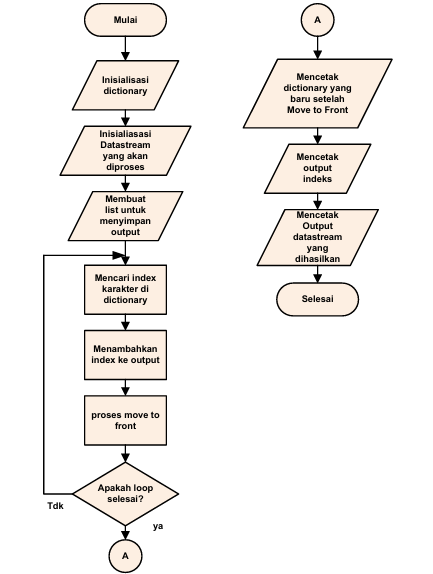



---




© Prof. Hertog Nugroho & Muhammad Yusuf Fadhlan, SST., M.Sc.

Politeknik Negeri Bandung (2023)